# Holdout Backtesting

## Load Backtest Inputs

- **Purpose:** Load and validate inputs for evaluating the explicitly selected Meta and Primary configurations; run meta modeling first. This notebook is independent of other backtesting notebooks.
- **Input:** Prepared events, split manifest, primary model, meta-model bundle, saved predictions, and market data.
- **Output:** Validated backtest inputs in memory for the following prediction, sizing, simulation, and statistics stages.
- **STRATEGY:** `sentiment_asynchronous` — Choose the matching model artifacts and execution rules.
- **PARTITION:** `holdout` — Use the fixed holdout evaluation window.
- **MANIFEST_PATH:** `data/preprocessing/universe/sp500_2025.csv` — Fix the research universe across stages.
- **DATA_START:** `2025-01-01 UTC` — Include January preparation observations before the research period.
- **RESEARCH_START:** `2025-02-01 UTC` — Set the inclusive research start and the first date in artifact filenames.
- **RESEARCH_END:** `2026-07-01 UTC` — Set the exclusive research end; artifact filenames use the preceding date.
- **settings:** `horizon_bars=1560`, `horizontal_multipliers=[5.0, 5.0]`, `max_positions_per_side=10`, `step_size=0.10`, `half_life_minutes=780.0`, `initial_aum=100_000.0`, `broker_fee_bps=1.0`, `slippage_bps=1.0` — Set holding horizon, the total position limit per direction in the single book, sizing, initial capital, and trading costs.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from src.backtesting.backtesting_workflow import (
    load_backtest_inputs, development_predictions, holdout_predictions,
    prepare_bet_sizing, simulate_portfolios, summarize_backtests, save_backtest_results,
)
from src.backtesting.portfolio_management import PortfolioSettings
from src.preprocessing.market_data import ResearchPaths

PROJECT_ROOT = Path.cwd().resolve().parents[2]

STRATEGY = "sentiment_asynchronous"
PARTITION = "holdout"

MANIFEST_PATH = PROJECT_ROOT / "data/preprocessing/universe/sp500_2025.csv"

DATA_START = pd.Timestamp("2025-01-01", tz="UTC")
RESEARCH_START = pd.Timestamp("2025-02-01", tz="UTC")
RESEARCH_END = pd.Timestamp("2026-07-01", tz="UTC")

settings = PortfolioSettings(
    horizon_bars=1560,
    horizontal_multipliers=[5.0, 5.0],
    max_positions_per_side=10, step_size=0.10, half_life_minutes=780.0,
    initial_aum=100_000.0, broker_fee_bps=1.0, slippage_bps=1.0,
)

paths = ResearchPaths(PROJECT_ROOT, model_kind="sentiment", start=RESEARCH_START, end=RESEARCH_END)

In [2]:
inputs = load_backtest_inputs(
    paths, settings, strategy=STRATEGY, partition=PARTITION,
    manifest_path=MANIFEST_PATH,
    data_start=DATA_START, end=RESEARCH_END,
)

## Holdout Predictions

- **Purpose:** Validate saved holdout predictions without refitting, tuning, or selecting a winner on holdout.
- **Input:** Family-tagged holdout predictions, fixed event/partition keys, and canonical primary predictions.
- **Output:** Validated predictions in memory; missing/duplicate events, mixed partitions, or inconsistent primary predictions are rejected.

In [3]:
validation_settings = None
splits = None
predictions = holdout_predictions(inputs)

## Bet Sizing

- **Purpose:** Prepare signed signals with split-training-only price calibration; rank eligible candidates by meta probability and session-time decay.
- **Input:** Frozen-model out-of-sample predictions and training-only calibration data.
- **Output:** Events and aligned calibration tables; the execution engine uses the latest signal per symbol and equal capital slots.


In [4]:
prepared = prepare_bet_sizing(inputs, predictions, splits)

## Portfolio Management

- **Purpose:** Execute independent family/path accounts using a shared completed dollar-bar stream.
- **Execution:** Observe completed bars, decide causally, and fill only on a later own-symbol bar; enforce fixed entry limits, reduction-before-increase execution, and final-bar liquidation.
- **Selection:** Select new symbols initially, on event termination, or after completed liquidation. Other registrations update the bounded priority queue; limit violations cancel without replacement.
- **Signals:** Each new event supersedes the symbol's previous signal and restarts its own barrier clock. A rejected or directionless latest signal closes the position; superseded signals cannot return.
- **Allocation:** For `n` selected symbols on a side, target `side * min(0.5 / n, 1 / K)` of current AUM. With `K=10`, each symbol is capped at 10%; each side uses at most 50%. Unused capacity stays in cash. Resize on membership changes, not probability changes alone.
- **Recording:** The simulation retains minute-last, fills, session-close and terminal/boundary observations.


In [5]:
accounts = simulate_portfolios(inputs, prepared, show_progress=True)

Preparing dollar bars


Dollar bars:   0%|          | 0/8899632 [00:00<?, ?bar/s]

## Backtest Statistics

- **Purpose:** Summarize account, classification, and holding metrics without resimulating.
- **Input:** Existing accounts, out-of-sample predictions, and returns for the selected benchmark symbol.
- **Output:** One selected-model statistics table and one cumulative-return graph; save `statistics.parquet` and `settings.json` under `data/backtesting/sentiment_asynchronous/holdout`. Account curves, detailed trades, and intermediate predictions remain in memory; see the [storage decision](../../../docs/decisions.md#12-database).
- **Display:** For the explicitly selected model family, show only `general_characteristics`, `performance`, `runs`, `implementation_shortfall`, `efficiency`, and `classification_scores` in this code-definition order by path, followed by its path return curves. Rows identify section, metric, and unit; classification metric names use `primary_` or `meta_` prefixes instead of an entity column; Primary reports precision/recall/F1 for both -1 and +1, Meta for class 1, and both report accuracy, positive log loss, PR-AUC, and ROC-AUC using the shared modeling calculations; no classification graphs are added; recompute statistics before rerunning display to obtain the new metrics; no rows or columns are abbreviated. Within each section, retain the original metric order. Other sections remain in the saved statistics. Model-family headings are omitted; graph titles show only strategy and partition. Rerun only the display cell when `statistics` and `accounts` are already available.
- **benchmark_symbol:** `SPY` — Select the market benchmark; local dollar bars must cover the evaluation interval and provide a starting anchor.
- **periods_per_year:** `365.25` — Annualize the calendar-day account series.
- **annual_risk_free_rate:** `0.03` — Use the assumed annual risk-free rate in risk-adjusted statistics.
- **annualized_benchmark_sharpe_ratio:** `1.0` — Set the reference Sharpe for probabilistic Sharpe evaluation.

In [6]:
evaluation_settings = dict(
    benchmark_symbol="SPY",
    periods_per_year=365.25, annual_risk_free_rate=0.03,
    annualized_benchmark_sharpe_ratio=1.0,
)

statistics = summarize_backtests(inputs, predictions, accounts, **evaluation_settings)

holdout
section                  metric                          unit                                        
general_characteristics  start                           timestamp   2025-10-24T13:51:24.469462+00:00
                         end                             timestamp          2025-12-31T21:00:00+00:00
                         average_aum                     USD                         97044.2537923437
                         leverage                        ratio                     0.6581206022080631
                         maximum_dollar_position_size    USD                         100941.013127178
                         ratio_of_longs                  ratio                     0.5674157303370787
                         frequency_of_bets               count/year                1903.8580609839241
                         average_holding_period          days                      1.5979957693232416
                         annualized_turnover             ratio                      350.6078745829464
                         correlation_to_underlying       ratio                    0.02034625774759817
performance              pnl                             USD                       -3550.704989552847
                         annualized_rate_of_return       ratio                   -0.17579986717620688
                         pnl_from_long_positions         USD                       -3712.740085649273
                         pnl_from_short_positions        USD                       162.03509609648677
                         hit_ratio                       ratio                    0.43820224719101125
                         average_return_from_hits        ratio                  0.0015814141084874707
                         average_return_from_misses      ratio                 -0.0014103443995439969
runs                     hhi_positive_returns            ratio                   0.002995716386913125
                         hhi_negative_returns            ratio                   0.003919948602368183
                         hhi_time_between_bets           ratio                   0.049528153010983504
                         percentile_drawdown             ratio                   0.005123617192595405
                         percentile_time_under_water     years                   0.006927714397035889
implementation_shortfall broker_fees_per_turnover        ratio                 0.00010000000358094414
                         average_slippage_per_turnover   ratio                 0.00010000000000000032
                         dollar_performance_per_turnover ratio                 -0.0005580944049625859
                         return_on_execution_costs       ratio                    -2.7904719748503033
efficiency               sharpe_ratio                    ratio                   -0.13103787820218069
                         annualized_sharpe_ratio         ratio                     -2.504332355647352
                         probabilistic_sharpe_ratio      ratio                    0.04451378432426588
classification_scores    primary_accuracy                score                     0.5882803487460496
                         primary_precision_-1            score                     0.5926991297157078
                         primary_recall_-1               score                     0.5521128413205226
                         primary_f1_-1                   score                     0.5716865456243281
                         primary_precision_1             score                     0.5844614446837421
                         primary_recall_1                score                     0.6241120995294874
                         primary_f1_1                    score                       0.60363634647169
                         primary_log_loss                score                     0.6699218655686567
                         primary_pr_auc                  score                     0.6245171907523497
              

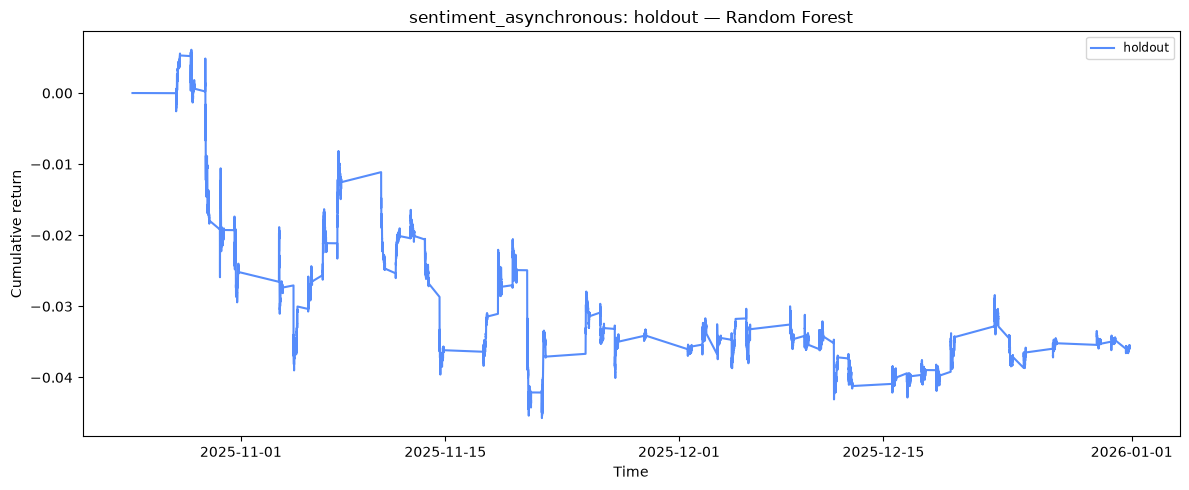

In [7]:
for family in statistics["model_family"].drop_duplicates():
    family_statistics = statistics.loc[statistics["model_family"].eq(family)].set_index(
        ["section", "metric", "unit"],
    )
    display_values = family_statistics.drop(columns="model_family")
    with pd.option_context(
        "display.max_rows", None, "display.max_columns", None,
        "display.max_colwidth", None,
    ):
        display(display_values)

    fig, ax = plt.subplots(figsize=(12, 5))
    for (account_family, path), result in accounts.items():
        if account_family == family:
            ledger = result["ledger"]
            ax.plot(ledger.timestamp, ledger.aum / settings.initial_aum - 1, label=path)
    ax.set(
        title=f"{STRATEGY}: {PARTITION}",
        ylabel="Cumulative return", xlabel="Time",
    )
    ax.legend(fontsize="small", ncol=3)
    fig.tight_layout()
    plt.show()

In [8]:
result_directory = save_backtest_results(
    inputs, statistics,
    evaluation_settings=evaluation_settings, validation_settings=validation_settings,
)
print(result_directory)

/Users/kwonjunhyuk9/Documents/financial-machine-learning/data/backtesting/sentiment_asynchronous/holdout
